# Phase 1 — Dataset inspection and validation

**Goal:** find out what `EEG_Scaled_data.csv` really contains *before* doing any signal processing.

The Kaggle description makes claims (11,233 rows, 36,864 signal columns, 1,434 seizure rows, standard-scaled). We treat all
of them as **claims to verify**. The most important question is: *how are the 36,864 numbers in one row arranged?*
A column called `Channel_123` is not necessarily an electrode. The answer decides which DSP steps in Phases 2-3 are valid.

**Source facts (from the PhysioNet CHB-MIT page, not from this CSV):** the original recordings are EDF files, 256 samples/s,
16-bit, mostly 23 channels, 22 subjects. Whether the Kaggle creator kept 256 Hz, which channels they used and how they cut the
segments is **not documented on the Kaggle page**, so we do not assume it.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from eeg_signal_classification import data_loader as dl, preprocessing as pp
from eeg_signal_classification.utils import (CSV_PATH, REPORTED_BY_CREATOR, RESULTS_DIR, SIGNAL_CACHE,
                                             STRUCTURE_FILE, ensure_dirs, save_json, set_seed)

ensure_dirs(); set_seed(); sns.set_theme(style="whitegrid")
(RESULTS_DIR / "figures").mkdir(exist_ok=True)
print("CSV path:", CSV_PATH)
dl.check_csv_exists()   # clear error message if the file is missing

CSV path: C:\eeg\EEG_Scaled_data.csv


WindowsPath('C:/eeg/EEG_Scaled_data.csv')

## 1. First look: read only 5 rows

In [3]:
head = dl.read_head(5)
print("shape of the 5-row preview:", head.shape)
display(head.iloc[:, [0, 1, 2, 3, -3, -2, -1]])
print(head.dtypes.value_counts())
header_report = dl.validate_header(head.columns)
print("header check:", header_report)

shape of the 5-row preview: (5, 36865)


,Channel_1,Channel_2,Channel_3,Channel_4,Channel_36863,Channel_36864,target
0,0.647,0.149,-0.213,-0.199,0.175,0.347,0
1,-2.450,-2.788,-2.387,-1.370,0.113,0.085,0
2,-0.026,-0.123,-0.347,-0.348,0.082,0.133,0
3,-0.067,-0.153,-0.180,-0.210,-0.127,-0.296,0
4,-0.190,-0.299,-0.333,-0.199,0.191,0.106,0


float64    36864
int64          1
Name: count, dtype: int64
header check: {'n_columns': 36865, 'n_signal_columns': 36864, 'problems': []}


## 2. One chunked pass over the whole file

`build_cache_and_summary` reads the CSV in chunks of 250 rows (never the whole 2.65 GB at once), and in the same pass:
checks that every signal column is numeric, counts NaN/inf, hashes rows to find duplicates, accumulates per-column mean/std,
counts labels, and writes a float32 `.npy` copy under `data/processed/` that later notebooks open as a memory map.
The first run takes a few minutes; later runs reuse the cache.

In [4]:
summary = dl.build_cache_and_summary()
pd.Series(summary).to_frame("value")

,value
csv_file,EEG_Scaled_data.csv
csv_size_gb,2.647
n_rows,11233
n_columns,36865
n_signal_columns,36864
header_problems,[]
all_signal_columns_numeric,True
n_nan_values,0
n_inf_values,0
n_duplicate_rows,877


## 3. Compare with what the dataset creator reported

In [5]:
counts = {int(k): int(v) for k, v in summary["label_counts"].items()}
mapping = dl.infer_label_mapping(counts, REPORTED_BY_CREATOR["n_seizure"], REPORTED_BY_CREATOR["n_non_seizure"])
observed = {"n_rows": summary["n_rows"], "n_columns": summary["n_columns"],
            "n_signal_columns": summary["n_signal_columns"],
            "n_non_seizure": counts.get(mapping["non_seizure_label"]),
            "n_seizure": counts.get(mapping["seizure_label"])}
compare = pd.DataFrame({"reported_by_creator": REPORTED_BY_CREATOR, "observed": observed})
compare["match"] = compare["reported_by_creator"] == compare["observed"]
display(compare)
print("label mapping:", mapping)
print("duplicate rows:", summary["n_duplicate_rows"], "| NaN:", summary["n_nan_values"], "| inf:", summary["n_inf_values"],
      "| constant columns:", summary["n_constant_columns"])

,reported_by_creator,observed,match
n_rows,11233,11233,True
n_columns,36865,36865,True
n_signal_columns,36864,36864,True
n_non_seizure,9799,9799,True
n_seizure,1434,1434,True


label mapping: {'seizure_label': 1, 'non_seizure_label': 0, 'status': 'inferred: observed class counts match the counts reported by the dataset creator'}
duplicate rows: 877 | NaN: 0 | inf: 0 | constant columns: 0


## 4. Class distribution

The labels are stored as numbers. The Kaggle page does not say which number is the seizure class, so we match the observed
counts to the counts the creator reported. That gives an *inferred* mapping, which we record as inferred and not as documented.

,label,count,percent,meaning
0,0,9799,87.23,non-seizure (inferred)
1,1,1434,12.77,seizure (inferred)


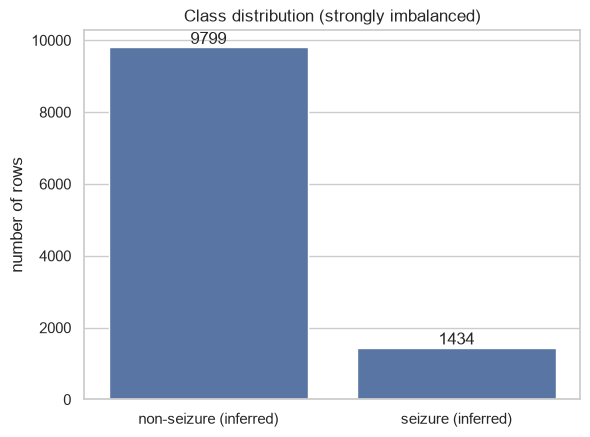

In [6]:
label_counts = pd.DataFrame({"label": list(counts), "count": list(counts.values())})
label_counts["percent"] = (100 * label_counts["count"] / label_counts["count"].sum()).round(2)
label_counts["meaning"] = label_counts["label"].map({mapping["seizure_label"]: "seizure (inferred)",
                                                      mapping["non_seizure_label"]: "non-seizure (inferred)"})
display(label_counts)
ax = sns.barplot(data=label_counts, x="meaning", y="count")
ax.set(title="Class distribution (strongly imbalanced)", xlabel="", ylabel="number of rows")
for bar, n in zip(ax.patches, label_counts["count"]):
    ax.annotate(str(n), (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom")
plt.savefig(RESULTS_DIR / "figures" / "01_class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. What preprocessing was already applied?

The creator says the data were standard-scaled. If that is `StandardScaler` applied **per column across all rows**, every column
has mean ~0 and std ~1 over the dataset. We check this from the running sums collected in the scan.
Note what this does *not* tell us: nothing about band-pass filtering or notch filtering that may have happened earlier.

{'column_means_near_0': True, 'column_stds_near_1': True, 'consistent_with_column_wise_standard_scaling': True}


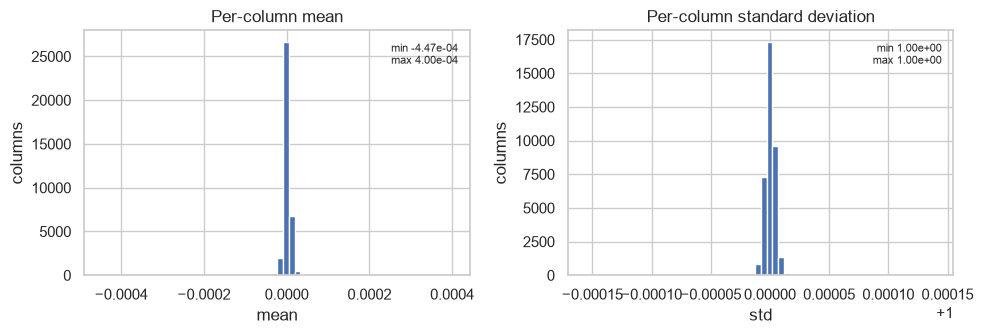

In [7]:
scaling = pp.check_standard_scaling(summary)
print(scaling)
col_mean = np.load(SIGNAL_CACHE.with_name("column_mean.npy")); col_std = np.load(SIGNAL_CACHE.with_name("column_std.npy"))
def safe_hist(ax, values, title, xlabel):
    lo, hi = float(values.min()), float(values.max())
    if hi - lo < 1e-6:                      # (almost) identical values: give the histogram a visible range
        lo, hi = lo - 1e-3, hi + 1e-3
    ax.hist(values, bins=60, range=(lo, hi)); ax.set(title=title, xlabel=xlabel, ylabel="columns")
    ax.text(0.97, 0.95, f"min {values.min():.2e}\nmax {values.max():.2e}", transform=ax.transAxes, ha="right", va="top", fontsize=8)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
safe_hist(axes[0], col_mean, "Per-column mean", "mean")
safe_hist(axes[1], col_std, "Per-column standard deviation", "std")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "figures" / "01_column_scaling.png", dpi=150); plt.show()

## 6. How is one row organised? (the key investigation)

If a row is a waveform, neighbouring columns are strongly related. We measure, for every pair of neighbouring columns,
`r_j = E[(x_{j+1} - x_j)^2] / (Var(x_j) + Var(x_{j+1}))` over ~1,500 random rows.

* `r ≈ 1`: neighbouring columns are independent → **not** a waveform.
* `r` well below 1 (≈ 1 − lag-1 correlation): smooth, waveform-like.
* If a row stores several channels back-to-back, `r` jumps up at each channel boundary, at regular spacing.

The function `investigate_structure` turns this into one of three verdicts: `blocks`, `single_sequence` or `unverified`.

memory-mapped signals: (11233, 36864) float32


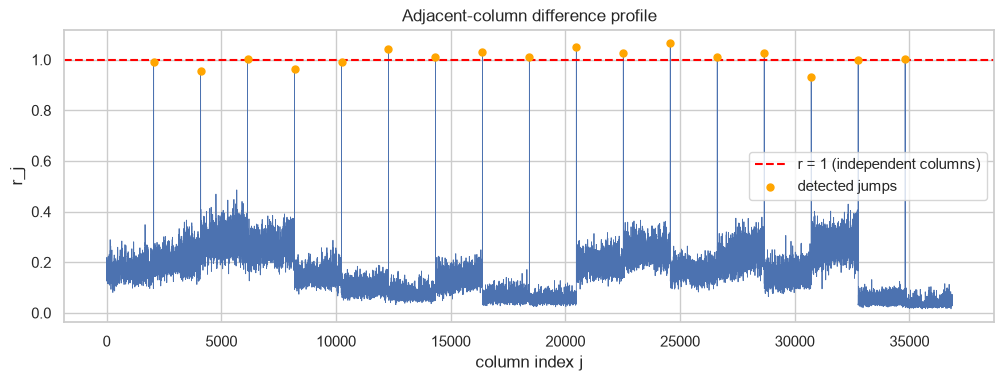

{'n_rows_used': 1500,
 'n_columns': 36864,
 'median_adjacent_ratio': 0.15441946868630677,
 'approx_lag1_correlation': 0.8455805313136933,
 'n_boundary_candidates': 17,
 'best_block_fit': {'block_length': 2048,
  'precision': 1.0,
  'recall': 1.0,
  'f1': 1.0},
 'short_lag_periodicity': {'lag': 2, 'strength': 0.860653211457963},
 'block_length': 2048,
 'n_blocks': 18,
 'layout': 'blocks',
 'note': 'Equal-length contiguous segments detected from regular jumps in adjacent-column difference.'}

In [8]:
signals = dl.open_signals(); labels = dl.load_labels()
print("memory-mapped signals:", signals.shape, signals.dtype)
X_sample = pp.sample_rows_evenly(signals, n_rows=1500)
structure = pp.investigate_structure(X_sample)
profile = pp.adjacent_column_profile(X_sample)
candidates = pp.find_boundary_candidates(profile)

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(profile, lw=0.6)
ax.axhline(1.0, color="red", ls="--", label="r = 1 (independent columns)")
ax.scatter(candidates, profile[candidates], color="orange", s=25, zorder=3, label="detected jumps")
ax.set(title="Adjacent-column difference profile", xlabel="column index j", ylabel="r_j"); ax.legend()
fig.savefig(RESULTS_DIR / "figures" / "01_adjacent_profile.png", dpi=150, bbox_inches="tight"); plt.show()
{k: v for k, v in structure.items() if k != "boundary_candidates_head"}

In [9]:
print("VERDICT:", structure["layout"], "-", structure["note"])
print(f"approx. lag-1 correlation between neighbouring columns: {structure['approx_lag1_correlation']:.3f}")
if structure["layout"] == "blocks":
    print(f"-> {structure['n_blocks']} contiguous blocks of {structure['block_length']} samples each "
          f"(best-fit precision {structure['best_block_fit']['precision']:.2f}, recall {structure['best_block_fit']['recall']:.2f})")
    print("   These are 'blocks' (likely channels, but NOT confirmed to be physical electrodes).")
elif structure["layout"] == "single_sequence":
    print("-> the row behaves like one continuous sequence of", structure["n_columns"], "samples")
else:
    print("-> Spectral / temporal analysis is NOT justified. Phases 2-3 will only use order-independent statistics.")

VERDICT: blocks - Equal-length contiguous segments detected from regular jumps in adjacent-column difference.
approx. lag-1 correlation between neighbouring columns: 0.846
-> 18 contiguous blocks of 2048 samples each (best-fit precision 1.00, recall 1.00)
   These are 'blocks' (likely channels, but NOT confirmed to be physical electrodes).


## 7. Row order and recording identifiers

There is no patient ID, recording ID or timestamp column. The only way the file could leak that information is through row
order. We look at how the labels are arranged along the rows.

number of label runs: 141
  label 0: 71 runs, mean run length 138.0, longest 657
  label 1: 70 runs, mean run length 20.5, longest 59


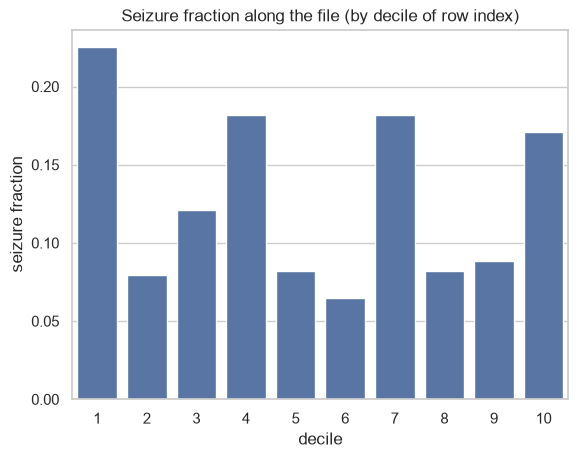

Rows look ORDERED (long label runs): False


In [10]:
change_points = np.flatnonzero(np.diff(labels)) + 1
run_lengths = np.diff(np.concatenate([[0], change_points, [len(labels)]]))
run_labels = labels[np.concatenate([[0], change_points])]
print("number of label runs:", len(run_lengths))
for cls in np.unique(labels):
    runs = run_lengths[run_labels == cls]
    print(f"  label {cls}: {len(runs)} runs, mean run length {runs.mean():.1f}, longest {runs.max()}")
decile = np.array_split(np.arange(len(labels)), 10)
seizure_fraction = [float((labels[idx] == mapping["seizure_label"]).mean()) for idx in decile]
ax = sns.barplot(x=list(range(1, 11)), y=seizure_fraction)
ax.set(title="Seizure fraction along the file (by decile of row index)", xlabel="decile", ylabel="seizure fraction")
plt.savefig(RESULTS_DIR / "figures" / "01_label_order.png", dpi=150, bbox_inches="tight"); plt.show()
shuffled_like = len(run_lengths) > 0.5 * 2 * labels.mean() * (1 - labels.mean()) * len(labels)
print("Rows look randomly shuffled:" if shuffled_like else "Rows look ORDERED (long label runs):", shuffled_like)

## 8. Sampling rate: the point we must not guess

The CSV contains no sampling frequency. The *source* database is 256 Hz, and 36,864 = 144 × 256 happens to divide evenly,
but that is arithmetic, not evidence: the creator may have resampled, chosen other segment lengths, or kept a different number of channels.
By default we therefore analyse in **normalised frequency** (cycles/sample, 0 to 0.5). If you decide to accept 256 Hz as an explicit
assumption (for example for the presentation), set it below; every later figure and feature is then labelled as "assumed".

In [11]:
ASSUMED_FS_HZ = None   # keep None unless you deliberately accept an assumption, e.g. 256

## 9. Metadata audit: verified vs. missing

In [12]:
layout_text = {"blocks": f"{structure['n_blocks']} blocks x {structure['block_length']} samples (inferred from data)",
               "single_sequence": "one continuous sequence (no block boundaries detected)",
               "unverified": "NOT established"}[structure["layout"]]
audit = pd.DataFrame([
    ("File size, rows, columns", "verified", f"{summary['n_rows']} x {summary['n_columns']}, {summary['csv_size_gb']} GB"),
    ("All signal columns numeric, no NaN/inf", "verified", f"NaN={summary['n_nan_values']}, inf={summary['n_inf_values']}"),
    ("Duplicate rows", "verified", str(summary["n_duplicate_rows"])),
    ("Column-wise standard scaling", "consistent with creator's claim" if scaling["consistent_with_column_wise_standard_scaling"] else "NOT confirmed", str(scaling)),
    ("Meaning of target labels", mapping["status"].split(":")[0], f"seizure = {mapping['seizure_label']}, non-seizure = {mapping['non_seizure_label']}"),
    ("Row structure / segment layout", structure["layout"], layout_text),
    ("Physical channel arrangement (which electrode)", "MISSING", "blocks, if any, cannot be mapped to electrodes from this CSV"),
    ("Sampling frequency", "MISSING", "not in CSV; source database is 256 Hz but resampling is undocumented"),
    ("Segment duration in seconds", "MISSING", "depends on the sampling frequency"),
    ("Physical units (microvolts)", "LOST", "standard scaling turned values into dimensionless z-scores"),
    ("Existing band-pass / notch filtering", "UNKNOWN", "checked indirectly from the spectrum in Phase 2"),
    ("Patient / recording identifiers", "MISSING", "patient-independent evaluation is impossible with this CSV"),
    ("Temporal order / time stamps of rows", "MISSING", "see section 7 for hints from the label order"),
], columns=["item", "status", "evidence / consequence"])
pd.set_option("display.max_colwidth", 120); display(audit)

,item,status,evidence / consequence
0,"File size, rows, columns",verified,"11233 x 36865, 2.647 GB"
1,"All signal columns numeric, no NaN/inf",verified,"NaN=0, inf=0"
2,Duplicate rows,verified,877
3,Column-wise standard scaling,consistent with creator's claim,"{'column_means_near_0': True, 'column_stds_near_1': True, 'consistent_with_column_wise_standard_scaling': True}"
4,Meaning of target labels,inferred,"seizure = 1, non-seizure = 0"
5,Row structure / segment layout,blocks,18 blocks x 2048 samples (inferred from data)
6,Physical channel arrangement (which electrode),MISSING,"blocks, if any, cannot be mapped to electrodes from this CSV"
7,Sampling frequency,MISSING,not in CSV; source database is 256 Hz but resampling is undocumented
8,Segment duration in seconds,MISSING,depends on the sampling frequency
9,Physical units (microvolts),LOST,standard scaling turned values into dimensionless z-scores


## 10. What is scientifically valid from here?

* **Always valid:** per-row amplitude statistics, class distribution, supervised ML on features that do not depend on column order.
* **Valid only if the verdict above is `blocks` or `single_sequence`:** temporal features (line length, Hjorth) and spectral analysis
  (FFT, Welch PSD, STFT, band power) **in normalised frequency**.
* **Valid only if a sampling rate is explicitly assumed:** results in Hz and the named clinical bands (delta, theta, alpha, beta, gamma).
* **Never valid with this file:** patient-independent generalisation claims, electrode-level interpretation, clinical claims.

## 11. Save the decisions and summaries

In [13]:
decision = {
    "layout": structure["layout"], "block_length": structure["block_length"], "n_blocks": structure["n_blocks"],
    "structure_note": structure["note"], "approx_lag1_correlation": structure["approx_lag1_correlation"],
    "seizure_label": mapping["seizure_label"], "non_seizure_label": mapping["non_seizure_label"],
    "label_status": mapping["status"],
    "fs_hz": ASSUMED_FS_HZ,
    "fs_status": "user-assumed (NOT verified from the data)" if ASSUMED_FS_HZ else "unknown - analysis in normalised frequency",
    "standard_scaling_consistent": scaling["consistent_with_column_wise_standard_scaling"],
    "subject_ids_available": False, "patient_independent_evaluation_possible": False,
}
save_json(decision, STRUCTURE_FILE)
save_json({**summary, "header_report": header_report, "scaling_check": scaling, "reported_by_creator": REPORTED_BY_CREATOR},
          RESULTS_DIR / "dataset_summary.json")
label_counts.to_csv(RESULTS_DIR / "label_counts.csv", index=False)
audit.to_csv(RESULTS_DIR / "metadata_audit.csv", index=False)
print(sorted(p.name for p in RESULTS_DIR.iterdir()))

['.gitkeep', 'dataset_summary.json', 'figures', 'label_counts.csv', 'metadata_audit.csv', 'structure_decision.json']
